# 13 — The CF4 `Vpwf` error

EDD's `CF4_Groups_Velocities.csv` (Cosmicflows-4, Tully et al. 2023) publishes three peculiar
velocities per group:

- `Vpds` — Davis & Scrimgeour (2014): `(fV − 74.6·D)/(1 + 74.6·D/c)`. No logarithm.
- `Vpwf` — Watkins & Feldman (2015): `fV/(1 + fV/c) · ln(fV/(74.6·D))`.
- `Vpec` — `Vpds` ramped into `Vpwf` between Vls = 0 and 3,000 km/s; **equal to `Vpwf` beyond**.

Here `fV` is the redshift velocity with its cosmological correction, and `D` is the distance (Mpc,
H0 = 74.6) from the measured modulus `DMzp`.

**The finding.** EDD computed `Vpwf` with **log₁₀** in place of the natural log. Every published `Vpwf`,
and every `Vpec` beyond Vls = 3,000 km/s, is therefore **ln 10 = 2.303 times too small**. Used as u,
the published columns would put the density–velocity dipole, and fσ₈, 2.3× low.

This notebook puts that claim through one test bench, with four velocities side by side. It
uses only `CF4_Groups_Velocities.csv`, and all logic lives in
`dvcorr.pipeline.real_catalog_audit` (the same functions as notebook 11 §13, there with `Vpec` in place of `Vpds`).
The figures are drawn by `dvcorr.pipeline.vpwf_error_figures` in a publication style: color-blind-safe
Okabe–Ito colors with distinct markers and line styles, and lettered panels.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd

from dvcorr.pipeline import real_catalog_audit as audit
from dvcorr.pipeline import vpwf_error_figures as figures
from dvcorr.pipeline.real_catalogs import Cf4VelocityDefinitions, load_cf4_velocities

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

velocities = load_cf4_velocities()
definitions = Cf4VelocityDefinitions()
config = audit.AuditConfig()
labels = audit.VPWF_ERROR_LABELS

print(f"{velocities.path.name}  {velocities.title!r}  rows {len(velocities.table):,}")
print(definitions)

CF4_Groups_Velocities.csv  'CF4 All Group Velocities'  rows 38,057
Cf4VelocityDefinitions(h0=74.6, q0=-0.595, j0=1.0, ramp_velocity=3000.0)


## 1 — The four velocities and the three checks

| Velocity | What it is |
| --- | --- |
| `Vpds` (published) | EDD's column: Davis & Scrimgeour, no log, so on the right scale by construction — the reference |
| `Vpwf` (published) | EDD's column, as shipped |
| `Vpwf` rebuilt, ln | `fV/(1+fV/c)·ln(fV/H0·D)` from `fV` and `DMzp` — Watkins & Feldman as they derive it |
| `Vpwf` rebuilt, log₁₀ | the same with log₁₀ — what EDD computed |

Groups where any of them is undefined are **dropped, never filled with zero**: fV ≤ 0, where the log is
undefined and the published `Vpwf` carries a filler 0, and eDM = 0, the Cepheid/TRGB calibrator groups,
whose distance error is not given.

Three checks, each with a known answer for the right velocity:

1. **Identity** — median ratio to the published `Vpwf`. The log₁₀ rebuild must give 1 (it *is* EDD's
   formula); the ln rebuild exactly ln 10 = 2.303.
2. **Scale** — median ratio to `Vpds` where |v| ≪ cz. There ln(1+x) ≈ x, so every estimator of v must
   agree with `Vpds`: 1 for the right velocity, 1/ln 10 = 0.434 for a log₁₀ one. No error model enters.
3. **Noise** — Watkins & Feldman's own test (their Fig. 1). For objects whose error σ_u exceeds
   1,000 km/s the cosmic signal (~300 km/s) is negligible, so v/σ_u must be a **unit Gaussian** for the
   velocity σ_u is the error of. σ_u = (ln 10/5)·eDM·fV/(1+fV/c) is the error of the ln velocity
   (`velocity_error_from_modulus_error`).

*Verify yourself:* `np.log(10) * velocities.table.Vpwf` equals the ln rebuild to rounding, row by row.

In [2]:
vtest = audit.velocity_test_table(velocities, definitions)
print(f"groups: {len(velocities.table):,}  kept: {len(vtest):,}  dropped (fV <= 0 or eDM = 0): {len(velocities.table) - len(vtest):,}")
audit.velocity_test_summary(vtest, config, labels).round(4)

groups: 38,057  kept: 37,821  dropped (fV <= 0 or eDM = 0): 236


,median_ratio_to_published_vpwf,max_abs_difference_from_published_vpwf,median_ratio_to_vpds_linear,std_normalized_noise_dominated,n_identity,n_linear,n_noise_dominated
velocity,,,,,,,
Vpds (published),2.3228,18743.0000,1.0000,0.9591,30402,12602,32477
Vpwf (published),1.0000,0.0000,0.4370,0.4099,30402,12602,32477
"Vpwf rebuilt, ln",2.3026,11559.3439,1.0065,0.9438,30402,12602,32477
"Vpwf rebuilt, log10",1.0000,106.4533,0.4371,0.4099,30402,12602,32477


**Reading the summary.**

- **Identity.** The log₁₀ rebuild reproduces the published `Vpwf` (median ratio 1.0000; all but two rows
  agree within 5 km/s, the worst by 106 km/s, a row where EDD rounded an intermediate value
  differently). The ln rebuild is the published column times 2.3026 in every row. So the two candidates
  differ by exactly one constant, and EDD's column is the log₁₀ one. `Vpds` sits at 2.32 times the
  published `Vpwf`, not exactly ln 10 because the two forms part at second order in v/cz.
- **Scale.** Against `Vpds` in the linear regime (12,602 groups with 200 < |Vpds| < 0.1·fV), the ln
  rebuild gives 1.007 and the two log₁₀ columns 0.437, which is 1/ln 10. `Vpds` gives 1 by definition: it is the reference.
- **Noise.** For the 32,477 noise-dominated groups, std(v/σ_u) is 0.944 for the ln rebuild and 0.959 for
  `Vpds`, and 0.410 for both log₁₀ columns. eDM explains the scatter of the two right-scale velocities (and is a few per cent
  conservative); it *over*-explains the published `Vpwf` by ln 10. `Vpds` passes this test with no log
  at all, so the error is in the log base, not in eDM.

## 2 — Published `Vpwf` against the three others

The same three checks as pictures: the published `Vpwf` on the y-axis against `Vpds`, the ln rebuild and
the log₁₀ rebuild, every group as one point, square axes. Each panel gives the
median ratio Vpwf/x over groups with |x| > 200 km/s.

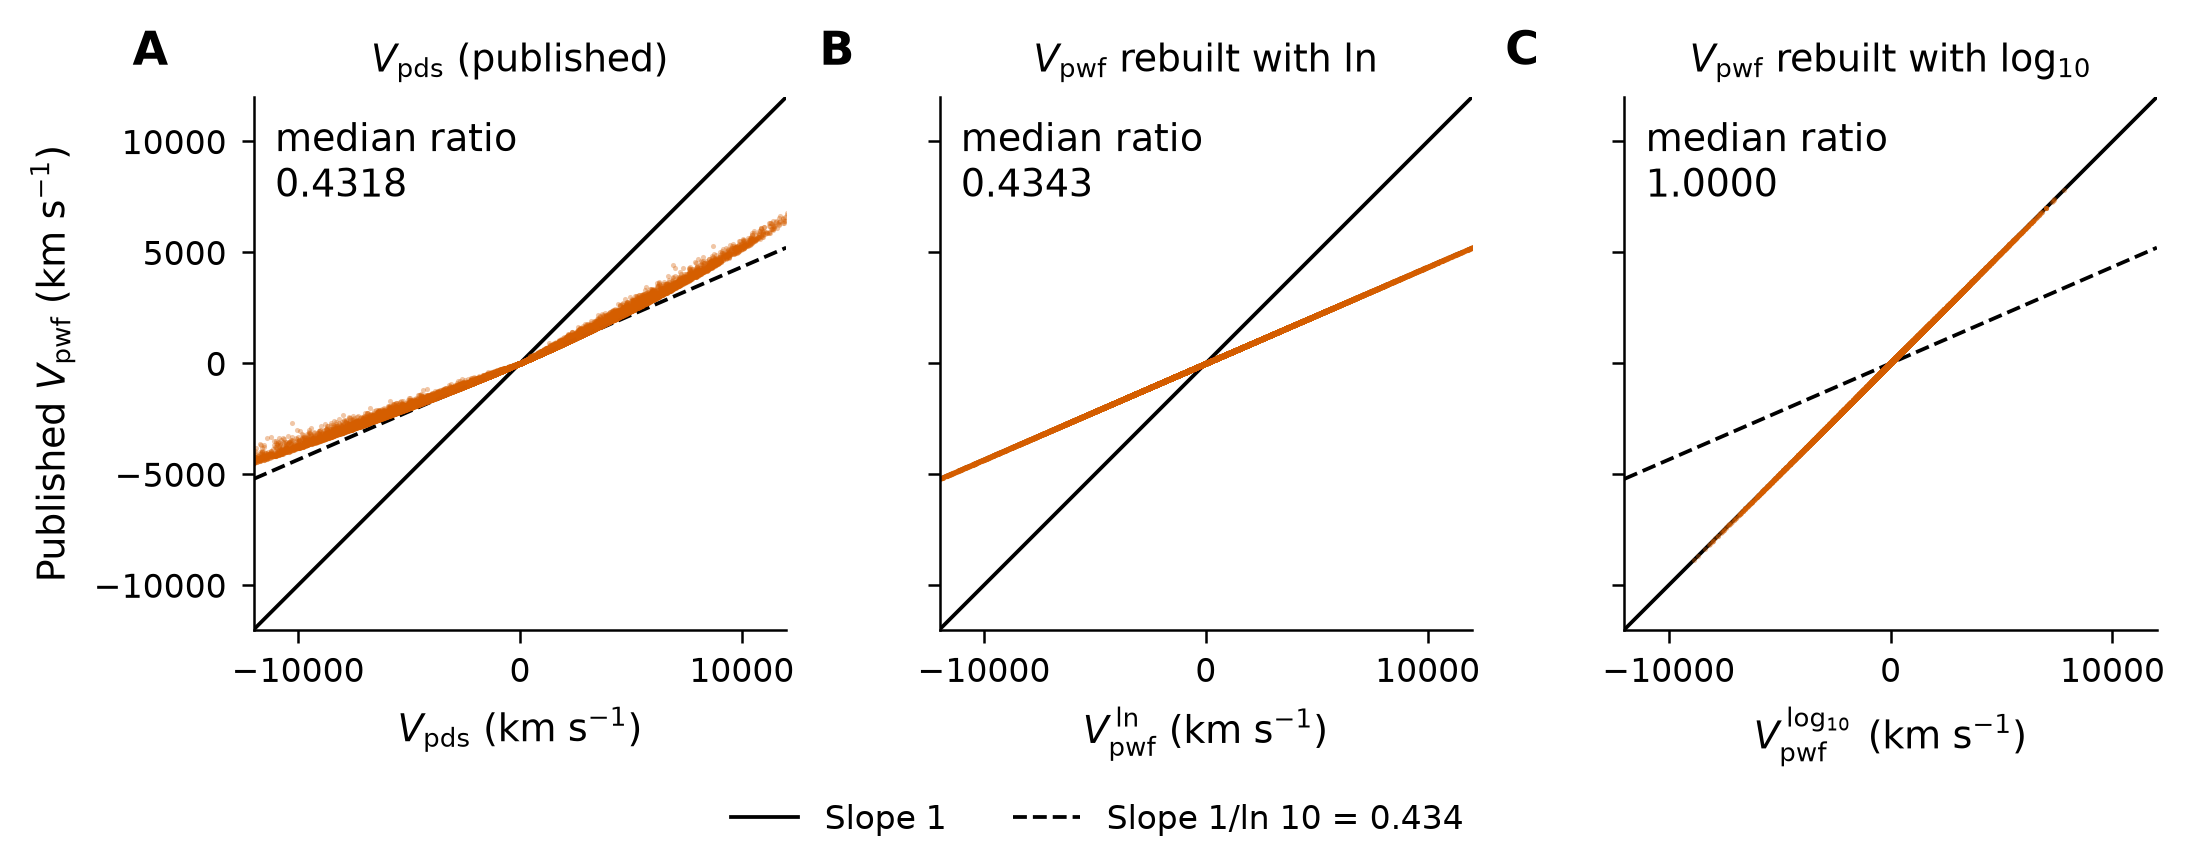

In [3]:
fig = figures.make_vpwf_comparison_figure(vtest, config)

**Reading it.**

- **Against `Vpds`** (left): near the origin, where |v| ≪ cz and every estimator must agree, the cloud
  runs along the dashed slope 1/ln 10, not the solid slope 1. Further out it bends *above* the dashed line on
  both sides. With y = H0·D/fV, ln(1/y) ≥ 1 − y for every y, so the log form is larger for positive v and
  smaller in magnitude for negative v. That curvature is the second-order difference between the two estimators,
  not scatter.
- **Against the ln rebuild** (middle): a thin line exactly on slope 1/ln 10 (median ratio 0.4343 = 1/ln 10).
  The published column is the ln velocity divided by a constant.
- **Against the log₁₀ rebuild** (right): exactly on slope 1. This is EDD's formula.

## 3 — The noise test

The histogram of v/σ_u over the noise-dominated groups, one panel per velocity.

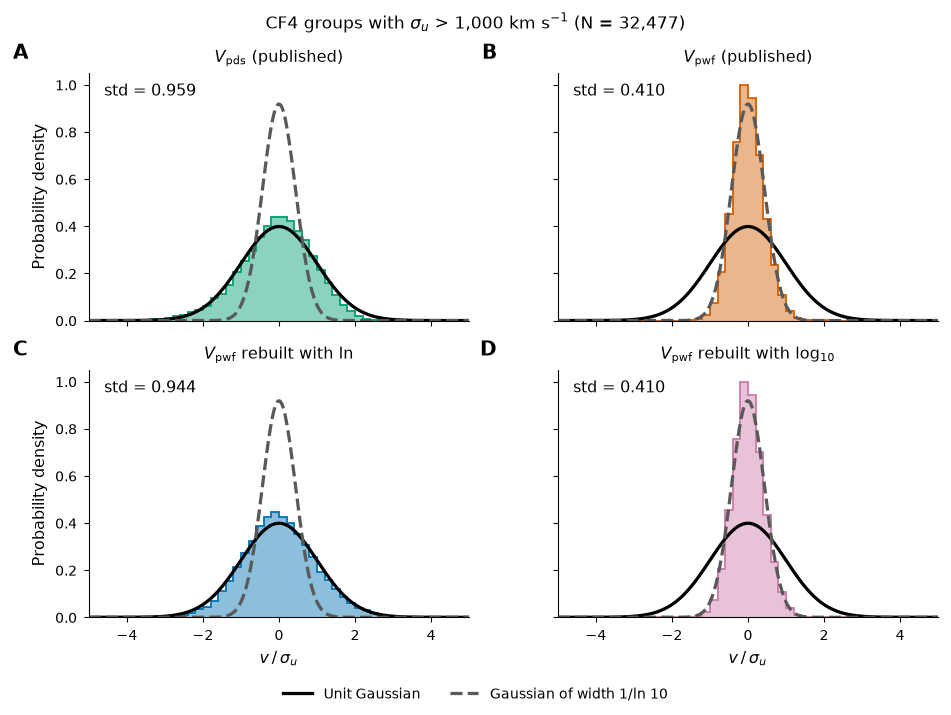

In [4]:
fig = figures.make_noise_histogram_figure(vtest, config, labels)

**What right looks like:** a histogram on the solid unit Gaussian. `Vpds` and the ln rebuild do; the
two log₁₀ columns sit on the dashed Gaussian of width 1/ln 10 = 0.434. That is 2.3× narrower than their own
errors allow, and no real error can produce it.

**By depth**, using every group (not only the noise-dominated ones):

,cz_lo,cz_hi,cz_median,n,Vpds (published),Vpwf (published),"Vpwf rebuilt, ln","Vpwf rebuilt, log10"
0,0.0,5000.0,3384.5,4454,2.111,0.769,1.775,0.771
1,5000.0,10000.0,7434.0,7436,0.995,0.427,0.983,0.427
2,10000.0,15000.0,12429.0,6277,0.972,0.418,0.963,0.418
3,15000.0,20000.0,17280.5,5092,0.988,0.421,0.970,0.421
4,20000.0,25000.0,22811.0,7377,0.960,0.410,0.944,0.410
5,25000.0,35000.0,27388.0,7185,0.918,0.393,0.906,0.393


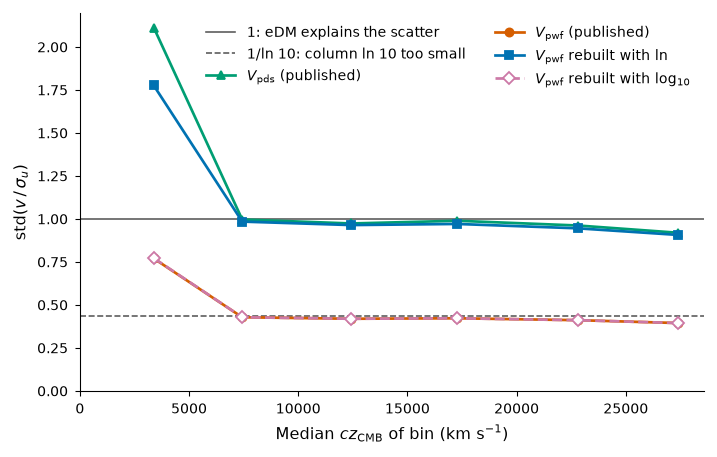

In [5]:
vtest_depth = audit.velocity_test_by_depth(vtest, config, labels)
display(vtest_depth.round(3))
fig = figures.make_noise_depth_figure(vtest_depth, labels)

**Reading it.** The published `Vpwf` (vermillion) is hidden under the dashed log₁₀ rebuild (pink, open
diamonds), the identity check again. Beyond 5,000 km/s both log₁₀ columns run along 1/ln 10 (0.43 → 0.39), and `Vpds` and the
ln rebuild run along 1 (0.99 → 0.92 and 0.98 → 0.91 with depth).

In the nearest bin both right-scale velocities sit *above* 1, `Vpds` at 2.11 and the ln rebuild at 1.78.
There σ_u is small enough that the cosmic signal shows on top of the noise. The gap between the two is in the
tails, not the scale. A robust width (1.4826 × the median absolute deviation of v/σ_u) in that bin is 1.15 for `Vpds` and 1.14
for ln. `Vpds`, linear in D rather than in the modulus, has the longer tails of a log-normal
error.

## 4 — Against redshift

The four columns with v on the y-axis and the CMB-frame cz (`Vcmb`) on the x-axis, one panel each, on
shared axes. Each panel carries the binned median (solid, 1,500 km/s bins), median ± the observed σ
(dashed), and median ± the σ_u that eDM predicts for the ln velocity (black dotted), over the density of all
groups, tinted in the panel's color. Both bands are
centered on the median, so their *widths* compare regardless of where the median goes. Binned on cz, the
distance error enters v only, so this is the clean version of the test: **for the right velocity, the
dashed band lies on the dotted one at every depth.**

,n,median Vpds (published),"median Vpwf rebuilt, ln",std/sigma_u Vpds (published),std/sigma_u Vpwf (published),"std/sigma_u Vpwf rebuilt, ln"
cz median,,,,,,
1206.0,503,-99.0,-93.05,1.61,0.66,1.51
2299.0,1335,-52.0,-51.18,1.22,0.51,1.18
3866.0,1679,11.0,10.47,1.08,0.45,1.03
5150.0,2426,-12.5,-12.53,1.00,0.43,0.99
6814.0,2344,24.5,24.18,0.98,0.42,0.96
8270.0,2128,-44.5,-44.21,1.00,0.42,0.96
9721.0,2187,8.0,7.75,0.99,0.42,0.96
11249.0,1895,50.0,50.12,0.97,0.41,0.95
12685.0,1723,30.0,29.70,1.00,0.42,0.96


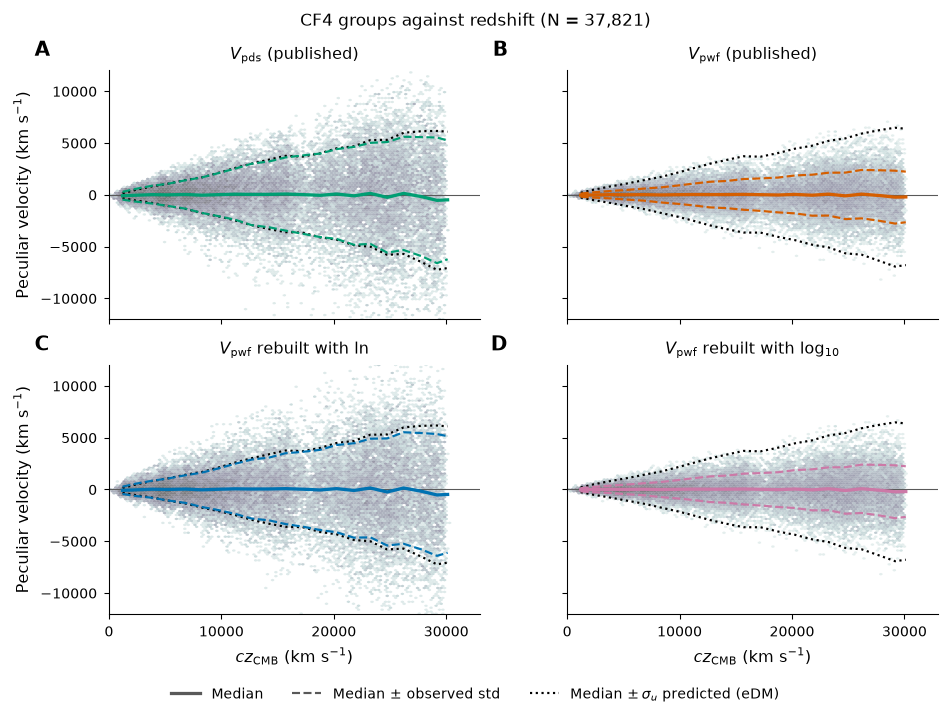

In [6]:
vtest_redshift = audit.velocity_test_binned(vtest, audit.VELOCITY_TEST_X_REDSHIFT, config, labels)
fig = figures.make_velocity_scatter_figure(vtest, vtest_redshift, audit.VELOCITY_TEST_X_REDSHIFT, config, labels)
rows = {label: vtest_redshift[vtest_redshift.velocity == label] for label in labels}
ln_rows = rows[audit.VELOCITY_VPWF_LN]
pd.DataFrame({
    "n": ln_rows.n.values,
    **{f"median {label}": rows[label]["median"].values
       for label in (audit.VELOCITY_VPDS_PUBLISHED, audit.VELOCITY_VPWF_LN)},
    **{f"std/sigma_u {label}": (rows[label]["std"] / rows[label].sigma_u_rms).values
       for label in (audit.VELOCITY_VPDS_PUBLISHED, audit.VELOCITY_VPWF_PUBLISHED, audit.VELOCITY_VPWF_LN)},
}, index=pd.Index(ln_rows.x_median.values, name="cz median")).round(2)

**Reading it.**

- **Width.** The ln rebuild's observed σ follows σ_u at every depth: std/σ_u = 0.99 at 5,000 km/s,
  0.95 around 20,000 and 0.88 near 29,000. eDM is right, and up to ~10% conservative at depth. `Vpds`
  tracks it 0.01–0.05 higher (1.00, 0.98, 0.91). The published `Vpwf` stays at ~0.41 all the way out,
  ln 10 inside the band its own errors predict.
- **Median.** `Vpds` and the ln rebuild have the same median in every bin, to about a km/s. Both are flat at zero. From
  3,000 to 28,000 km/s every bin's ln median lies within 2σ of zero, where σ is the standard error of
  a median, √(π/2)·std/√n. That is ~25 km/s at 5,000 km/s, growing to ~160 km/s at depth (largest:
  −252 km/s at 24,750, 2.0σ). A zero-point offset would show as a median growing linearly with cz;
  none does. Only the deepest well-populated bin departs: −540 km/s at 29,200 km/s (3.3σ), at the SDSS
  FP survey edge, where selection at fixed cz starts to bite. That is a Malmquist question, not a log-base one.

Compare this with the next figure, which bins the same velocities on measured distance.

## 5 — Against measured distance

The same plot with CF4's measured distance `D` (Mpc, on CF4's H0 = 74.6) on the x-axis instead of cz.
Here the distance error enters **both** axes, and the median stops being a flow measurement:

velocity,Vpds (published),Vpwf (published),"Vpwf rebuilt, ln","Vpwf rebuilt, log10"
x_median,,,,
18.484172,118.0,54.0,125.0,54.0
38.176858,154.0,69.0,158.0,68.0
63.503842,185.0,82.0,188.0,82.0
87.659704,193.0,86.0,196.0,85.0
111.892248,194.0,85.0,196.0,85.0
136.993516,238.0,105.0,242.0,105.0
162.106340,286.0,126.0,289.0,125.0
187.845156,402.0,177.0,407.0,177.0
212.275568,257.0,112.0,259.0,112.0


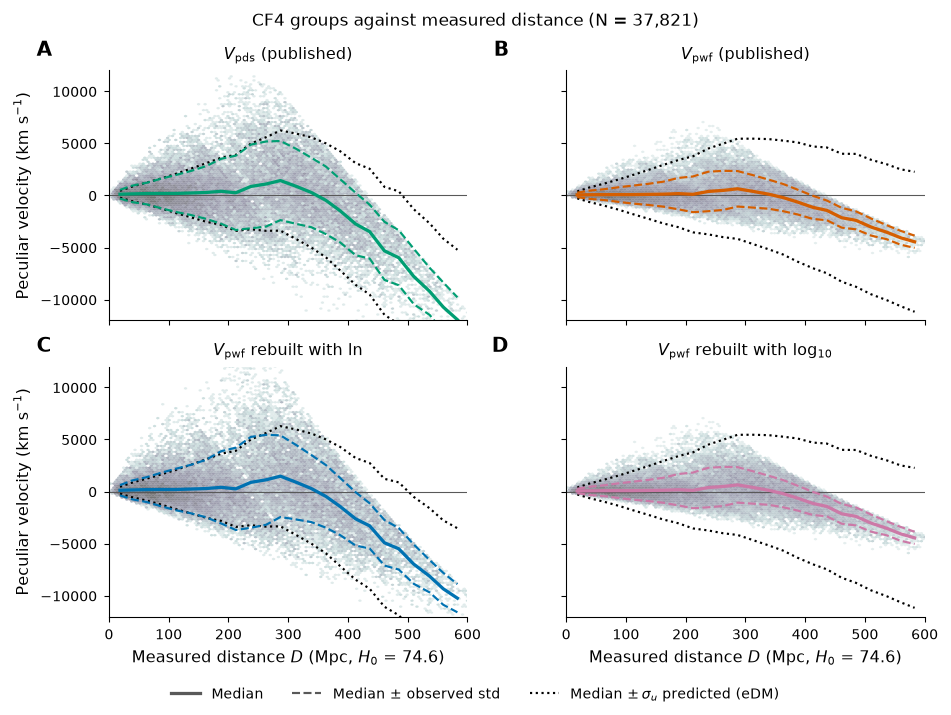

In [7]:
vtest_distance = audit.velocity_test_binned(vtest, audit.VELOCITY_TEST_X_DISTANCE, config, labels)
fig = figures.make_velocity_scatter_figure(vtest, vtest_distance, audit.VELOCITY_TEST_X_DISTANCE, config, labels)
vtest_distance.pivot(index="x_median", columns="velocity", values="median")[list(labels)].round(0)

**Reading it — two separate things.**

*The width* is the same test as against cz. Out to ~250 Mpc the bands of `Vpds` and the ln rebuild lie on
the black σ_u band (at D ≈ 112 Mpc: observed σ 1,771 and 1,991 km/s against a predicted 1,882), while the
published `Vpwf` is 2.3× narrower (865 km/s in the same bin).

*The median* is **not** a test of the columns. It has the same shape in all four panels, scaled by 1/ln 10 in
the log₁₀ ones. For the ln rebuild it stays at +100 to +400 km/s out to ~210 Mpc, rises to +1,475 km/s at
~290 Mpc, crosses zero near 350 Mpc and falls to −10,239 km/s at 583 Mpc. `Vpds` follows it and
falls further at depth (−11,929 km/s): far from the Hubble line the two forms part, as in section 2.
Binning on *measured* distance causes this. At fixed measured D, v ≈ cz·ln(cz/H0·D) is decided by where each group's cz lies
relative to H0·D, and that is set by the sample's n(cz), not by the flow:

- Up to the SDSS-FP peak (cz ≈ 24,000 km/s, H0·D ≈ 320 Mpc) more groups lie *beyond* H0·D than inside it,
  so a bin is dominated by groups scattered **inward** in distance, which gives positive v.
- Past the peak and the survey edge at cz ≈ 30,000 km/s (H0·D ≈ 400 Mpc), no group's cz reaches H0·D, so
  every group in the bin was scattered **outward**, which gives strongly negative v. The spread shrinks below σ_u
  there because cz is truncated, and the sharp diagonal upper edge of the cloud is that cz limit.

This is inhomogeneous Malmquist bias, a property of the sample's selection, not of the log base; it is
corrected later (roadmap Stage 4). It is also why the analysis places CF4 groups at their **redshift**
positions (as Nusser 2017 does) and never bins u on measured distance.

## 6 — What the literature says

Checked 2026-10-18:

- Watkins & Feldman (2015) write the estimator as `v = cz log(cz/H0 r)` with no base. Their proof that
  it is unbiased (eqs. 6–7), ⟨v⟩ = −cz log(1 − v/cz) ≈ v, holds **only for the natural log**. With log₁₀
  it gives v/ln 10.
- Tully et al. (2023), the CF4 paper, copies it as eq. (10) with the same bare "log", in a paper
  where "log" means log₁₀ ("log H"). That is the likely origin of the EDD column.
- Watkins et al. (2023, arXiv:2302.02028; Tully a co-author), applying the estimator to CF4, write it
  with an explicit **ln(10)** prefactor (their eq. 17). That is the factor missing from EDD's column.
- No erratum or paper was found stating that EDD's `Vpwf`/`Vpec` are low by ln 10.

**Verdict:** the ln rebuild is the peculiar velocity, and `Vpds`, which has no log in it, agrees with it on
scale, noise and median. The published `Vpwf`, and `Vpec` beyond Vls = 3,000 km/s, are ln 10 = 2.3× too
small. Using them as u would put the dipole, and fσ₈, 2.3× low for every such group.